Q1.  Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, technology, food, books, etc.).

 1. Convert text to lowercase and remove punctua on using re.

  2. Tokenize the text into words and sentences.
  
  3. Split using split() and word_tokenize() and compare how Python split and NLTK’s word_tokenize() differ.
  
  4. Remove stopwords (using NLTK's stopwords list).
  
  5. Display word frequency distribu on (excluding stopwords).

In [1]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Artificial intelligence is changing the world.
I enjoy learning about artificial intelligence and Python programming.
Technology helps people solve problems, automate tasks, and discover new ideas.
Python is especially useful because it is simple and powerful.
In the future, intelligent systems may improve education, healthcare, and daily life."""

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(clean_text))

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]

print("\nWords after removing stopwords:\n", filtered_words)

frequency = Counter(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in frequency.most_common():
    print(word, ":", count)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Cleaned Text:
 artificial intelligence is changing the world
i enjoy learning about artificial intelligence and python programming
technology helps people solve problems automate tasks and discover new ideas
python is especially useful because it is simple and powerful
in the future intelligent systems may improve education healthcare and daily life

Word Tokens:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'i', 'enjoy', 'learning', 'about', 'artificial', 'intelligence', 'and', 'python', 'programming', 'technology', 'helps', 'people', 'solve', 'problems', 'automate', 'tasks', 'and', 'discover', 'new', 'ideas', 'python', 'is', 'especially', 'useful', 'because', 'it', 'is', 'simple', 'and', 'powerful', 'in', 'the', 'future', 'intelligent', 'systems', 'may', 'improve', 'education', 'healthcare', 'and', 'daily', 'life']

Sentence Tokens:
 ['Artificial intelligence is changing the world.', 'I enjoy learning about artificial intelligence and Python programming.', 'Techno

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Q2. Using the same paragraph from Q1:

1. Extract all words with only alphabets using re.findall()

2. Remove stop words using NLTK’s stopword list

3. Perform stemming with PorterStemmer

4. Perform lemma za on with WordNetLemma zer

5. Compare the stemmed and lemma zed outputs and explain when you’d prefer one over the other.

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial intelligence is changing the world.
I enjoy learning about artificial intelligence and Python programming.
Technology helps people solve problems, automate tasks, and discover new ideas.
Python is especially useful because it is simple and powerful.
In the future, intelligent systems may improve education, healthcare, and daily life."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:\n", words)

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nAfter Stopword Removal:\n", filtered_words)

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]
print("\nStemmed Words:\n", stemmed_words)

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words]
print("\nLemmatized Words:\n", lemmatized_words)

print("\nComparison:")
for original, stem, lemma in zip(filtered_words, stemmed_words, lemmatized_words):
    print(f"{original:15} Stem: {stem:12} Lemma: {lemma}")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic Words:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'i', 'enjoy', 'learning', 'about', 'artificial', 'intelligence', 'and', 'python', 'programming', 'technology', 'helps', 'people', 'solve', 'problems', 'automate', 'tasks', 'and', 'discover', 'new', 'ideas', 'python', 'is', 'especially', 'useful', 'because', 'it', 'is', 'simple', 'and', 'powerful', 'in', 'the', 'future', 'intelligent', 'systems', 'may', 'improve', 'education', 'healthcare', 'and', 'daily', 'life']

After Stopword Removal:
 ['artificial', 'intelligence', 'changing', 'world', 'enjoy', 'learning', 'artificial', 'intelligence', 'python', 'programming', 'technology', 'helps', 'people', 'solve', 'problems', 'automate', 'tasks', 'discover', 'new', 'ideas', 'python', 'especially', 'useful', 'simple', 'powerful', 'future', 'intelligent', 'systems', 'may', 'improve', 'education', 'healthcare', 'daily', 'life']

Stemmed Words:
 ['artifici', 'intellig', 'chang', 'world', 'enjoy', 'learn', 'artifici'

Q3. Choose 3 short texts of your own (e.g., different news headlines, product reviews).

1. Use CountVectorizer to generate the Bag of Words representa on.

 2. Use TfidfVectorizer to compute TF-IDF scores.

 3. Print and interpret the top 3 keywords from each text using TF-IDF.

In [3]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps machines learn and solve problems.",
    "Python programming is useful for machine learning and data analysis.",
    "Blockchain technology provides secure and transparent digital transactions."
]

count_vectorizer = CountVectorizer(stop_words='english')
bow_matrix = count_vectorizer.fit_transform(texts)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out()
)

print("Bag of Words Representation:")
print(bow_df)

tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

print("\nTF-IDF Representation:")
print(tfidf_df.round(3))

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTop 3 Keywords from Each Text:")
for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]
    keywords = [(feature_names[j], round(row[j], 3)) for j in top_indices]
    print(f"Text {i + 1}: {keywords}")

Bag of Words Representation:
   analysis  artificial  blockchain  data  digital  helps  intelligence  \
0         0           1           0     0        0      1             1   
1         1           0           0     1        0      0             0   
2         0           0           1     0        1      0             0   

   learn  learning  machine  ...  problems  programming  provides  python  \
0      1         0        0  ...         1            0         0       0   
1      0         1        1  ...         0            1         0       1   
2      0         0        0  ...         0            0         1       0   

   secure  solve  technology  transactions  transparent  useful  
0       0      1           0             0            0       0  
1       0      0           0             0            0       1  
2       1      0           1             1            1       0  

[3 rows x 21 columns]

TF-IDF Representation:
   analysis  artificial  blockchain   data  digita

Q4. Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain).

1. Preprocess and tokenize both texts.

2. Calculate:

a. Jaccard Similarity using sets

b. Cosine Similarity using TfidfVectorizer + cosine_similarity()

c. Analyze which similarity metric gives be er insights in your case.

In [4]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence enables machines to learn from data.
AI systems recognize patterns, make predictions, and automate tasks.
They are used in healthcare, education, and business."""

text2 = """Blockchain stores digital transactions in a distributed ledger.
It improves transparency, security, and trust between participants.
Blockchain technology is used in finance and supply chains."""

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text.split()

words1 = preprocess(text1)
words2 = preprocess(text2)

print("Tokens in Text 1:\n", words1)
print("\nTokens in Text 2:\n", words2)

set1 = set(words1)
set2 = set(words2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nCommon Words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("Cosine Similarity:", round(cosine, 4))

if jaccard > cosine:
    print("Jaccard similarity is higher for these texts.")
elif cosine > jaccard:
    print("Cosine similarity is higher for these texts.")
else:
    print("Both similarity scores are equal.")

Tokens in Text 1:
 ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'ai', 'systems', 'recognize', 'patterns', 'make', 'predictions', 'and', 'automate', 'tasks', 'they', 'are', 'used', 'in', 'healthcare', 'education', 'and', 'business']

Tokens in Text 2:
 ['blockchain', 'stores', 'digital', 'transactions', 'in', 'a', 'distributed', 'ledger', 'it', 'improves', 'transparency', 'security', 'and', 'trust', 'between', 'participants', 'blockchain', 'technology', 'is', 'used', 'in', 'finance', 'and', 'supply', 'chains']

Common Words: {'used', 'and', 'in'}
Jaccard Similarity: 0.0698
Cosine Similarity: 0.0281
Jaccard similarity is higher for these texts.


Q5. Write a short review for a product or service.

1. Use TextBlob or VADER to find polarity & subjec vity for each review.

2. Classify reviews into Posi ve / Nega ve / Neutral.

3. Create a word cloud using the wordcloud library for all posi ve reviews.

Sentiment Analysis Results:

Review: This laptop is excellent and very fast.
Polarity: 0.63
Subjectivity: 0.89
Sentiment: Positive
--------------------------------------------------
Review: The battery life is amazing and the display is beautiful.
Polarity: 0.725
Subjectivity: 0.95
Sentiment: Positive
--------------------------------------------------
Review: The product is average and works as expected.
Polarity: -0.125
Subjectivity: 0.4
Sentiment: Negative
--------------------------------------------------
Review: The laptop is slow and the battery is terrible.
Polarity: -0.65
Subjectivity: 0.7
Sentiment: Negative
--------------------------------------------------
Review: Poor quality and disappointing performance.
Polarity: -0.5
Subjectivity: 0.65
Sentiment: Negative
--------------------------------------------------
Review: This is a good product with useful features.
Polarity: 0.5
Subjectivity: 0.3
Sentiment: Positive
--------------------------------------------------


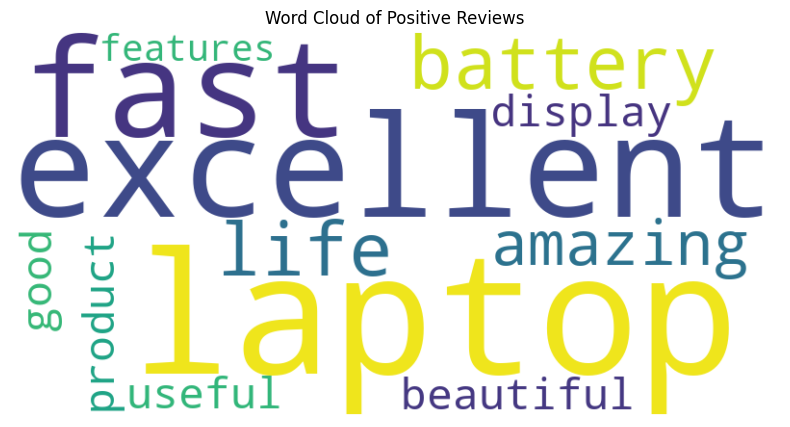

In [5]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This laptop is excellent and very fast.",
    "The battery life is amazing and the display is beautiful.",
    "The product is average and works as expected.",
    "The laptop is slow and the battery is terrible.",
    "Poor quality and disappointing performance.",
    "This is a good product with useful features."
]

positive_reviews = []
results = []

for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0.05:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    results.append((review, round(polarity, 3),
                    round(subjectivity, 3), sentiment))

print("Sentiment Analysis Results:\n")

for review, polarity, subjectivity, sentiment in results:
    print("Review:", review)
    print("Polarity:", polarity)
    print("Subjectivity:", subjectivity)
    print("Sentiment:", sentiment)
    print("-" * 50)

if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        collocations=False
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews available.")

Q6. Choose your own paragraph (~100 words) as training data.

1. Tokenize text using Tokenizer() from keras.preprocessing.text

2. Create input sequences and build a simple LSTM or Dense model

3. Train the model and generate 2–3 new lines of text star ng from any seed word you provide.

In [9]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """Artificial intelligence is transforming modern technology.
Machines can learn patterns from data and make useful predictions.
Machine learning helps computers improve through experience.
Deep learning uses neural networks to solve complex problems.
Python is a popular programming language for artificial intelligence.
Developers use Python to build intelligent applications.
Natural language processing helps computers understand human language.
Computer vision allows machines to analyze images and videos.
Artificial intelligence is used in healthcare, education, and business.
These technologies can automate tasks and improve productivity.
Data is important because intelligent systems learn from examples.
Researchers continue to develop safer and more efficient algorithms.
Machine learning can recognize patterns in large datasets.
Neural networks are inspired by the human brain.
Technology will continue to change how people work and learn."""

np.random.seed(42)
tf.random.set_seed(42)

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
token_list = tokenizer.texts_to_sequences([text])[0]

print("Vocabulary Size:", total_words)
print("Tokenized Sequence:\n", token_list)

sequences = []

for i in range(2, len(token_list) + 1):
    sequences.append(token_list[:i])

max_sequence_len = max(len(seq) for seq in sequences)

sequences = pad_sequences(
    sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = sequences[:, :-1]
y = sequences[:, -1]

y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=32,
        input_length=max_sequence_len - 1
    ),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

model.fit(X, y, epochs=100, verbose=0)

print("\nModel training completed.")

def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted_probs = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(predicted_probs))

        output_word = None

        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                output_word = word
                break

        if output_word is None:
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text 1:")
print(generate_text("artificial intelligence", 10))

print("\nGenerated Text 2:")
print(generate_text("machine learning", 10))

print("\nGenerated Text 3:")
print(generate_text("python", 10))

Vocabulary Size: 87
Tokenized Sequence:
 [4, 5, 3, 26, 27, 10, 11, 6, 7, 12, 13, 14, 1, 28, 29, 30, 15, 8, 16, 17, 18, 31, 32, 33, 8, 34, 19, 20, 2, 35, 36, 37, 21, 3, 38, 39, 40, 9, 41, 4, 5, 42, 43, 21, 2, 44, 22, 45, 46, 9, 47, 16, 17, 48, 23, 9, 49, 50, 51, 11, 2, 52, 53, 1, 54, 4, 5, 3, 55, 24, 56, 57, 1, 58, 59, 60, 6, 61, 62, 1, 18, 63, 14, 3, 64, 65, 22, 66, 7, 13, 67, 68, 25, 2, 69, 70, 1, 71, 72, 73, 15, 8, 6, 74, 12, 24, 75, 76, 19, 20, 77, 78, 79, 80, 23, 81, 10, 82, 25, 2, 83, 84, 85, 86, 1, 7]
Input Shape: (125, 125)
Output Shape: (125, 87)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Model training completed.

Generated Text 1:
artificial intelligence is is modern technology machines can learn patterns patterns data

Generated Text 2:
machine learning intelligence intelligence modern technology machines can learn patterns patterns data

Generated Text 3:
python is is is technology technology machines can learn patterns data
